In [ ]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
from src.data_loading import load_data, split_train_test_freq
from src.features import preparer, modalites_frequentes, regrouper, FORMULE_FREQUENCE_FINALE, appliquer_decisions_phase1, BINS_DRIVAGE_FIN, LABELS_DRIVAGE_FIN, FORMULE_SEVERITE_BASE, sans, formule_sev, TERMES_SEV_BASE, remplacer, colonnes_sev
from src.graph import plot_freq_par_groupe, freq_par_groupe, plot_facteurs, plot_exposition_par_modalite
from src.graph import plot_sev_par_groupe
from src.metrics import comparer_tranches, seuil_aic_lr, seuil_bic_lr, seuil_test_lr, comparer_modeles_glm, lift_table, gini, comparer_tranches_sev, table_severite, comparer_glm_gamma
from src.models import ajuster_gamma
from sklearn.metrics import mean_poisson_deviance
import numpy as np
import json
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [36]:
freq, sev = load_data()
train, test = split_train_test_freq(freq, test_size=0.2, random_state=42)

train = preparer(train, decoupage="grossier")
test  = preparer(test,  decoupage="grossier")

modalites = {}
ETIQUETTE_AUTRE = {"VehPower": "12+", "Region": "Autres", "VehBrand": "Autres"}

for col in ["Region", "VehBrand", "VehPower"]:
    modalites[col] = modalites_frequentes(train, col)
    train = regrouper(train, col, modalites[col], autre=ETIQUETTE_AUTRE[col])
    test  = regrouper(test,  col, modalites[col], autre=ETIQUETTE_AUTRE[col])


train = appliquer_decisions_phase1(train)
test = appliquer_decisions_phase1(test)

sev_train = sev.merge(train, on="IDpol", how="inner", validate="many_to_one")
sev_test  = sev.merge(test,  on="IDpol", how="inner", validate="many_to_one")

perdus = len(sev) - len(sev_train) - len(sev_test)
print(perdus)
print("Part du train : ", len(sev_train) / len(sev))


0
Part du train :  0.799122674330661


In [37]:
nb_lignes = sev_train.groupby("IDpol").size().rename("nb_lignes")
comp = train.set_index("IDpol").join(nb_lignes, how="inner")
print("Plus de lignes que ClaimNb :", (comp["nb_lignes"] > comp["ClaimNb"]).sum())
print("Moins de lignes que ClaimNb :", (comp["nb_lignes"] < comp["ClaimNb"]).sum())

Plus de lignes que ClaimNb : 5
Moins de lignes que ClaimNb : 1


On constate que 5 polices ont plus de ligne dans `sev` que dnas la variable `ClaimNB` de `freq`. Ces polices sont surement celle dont on a plafonné `ClaimNB` dans la phase d'exploration mais dont les montants correspondant sont resté dans `sev`. Le plafonnement de `ClaimNB` a été fait, il n'y a rien à faire.

1 police à moins de ligne dans `sev` que dans `ClaimNB` de `freq`. L'estimation du coût moyen porte sur les sinistres chiffrée uniquement, il n'y a donc rien a faire pour cette police.

Il est nécessaire pour l'estimation du coût moyen de ne pas inclure les sinistres de valeurs extrêmes car ils fausseraient l'estimation et pourraient conduire à des primes très élevées pour certaine tranche à faible exposition. Les montants des évênements extrêmes relevent du hasard et ne sont pas représentatif d'un profil de risque. Il est donc nécessaire de les plafonner pour l'estimation du coût moyen.

La solution est de plafonner chaque sinistre à un seuil et de redistribuer l'excédent sous forme d'un facteur de charge uniforme.

In [38]:
lignes = []
for q in [0.95, 0.975, 0.99, 0.995, 0.999]:
    s = sev_train["ClaimAmount"].quantile(q)
    exces = (sev_train["ClaimAmount"] - s).clip(lower=0)
    lignes.append({
        "quantile" : q,
        "seuil" : s, 
        "nb_au_dessus" : (sev_train["ClaimAmount"] > s).sum(),
        "part_charge_excedent" : exces.sum() / sev_train["ClaimAmount"].sum(),
        "kappa" : exces.sum() / sev_train["ClaimAmount"].clip(upper=s).sum()})

seuils = pd.DataFrame(lignes).round(3)
seuils



,quantile,seuil,nb_au_dessus,part_charge_excedent,kappa
0,0.950,4760.228,1057,0.428,0.748
1,0.975,8101.782,529,0.377,0.605
2,0.990,16351.621,212,0.322,0.474
3,0.995,33503.045,106,0.271,0.371
4,0.999,150131.075,22,0.169,0.204


Le choix d'un seuil au quantile 0.995 me semble approprié. J'ai peur qu'avec des seuils plus hauts, les valeurs extrêmes (au dessus de 35000 euros) faussent l'estimation du coût moyen pour des profils et modalités à faible exposition.

In [39]:
top = sev_train["ClaimAmount"].nlargest(10)
print(top)
print("Part de la charge porté par les 10 plus gros : ", sev_train["ClaimAmount"].nlargest(10).sum() / sev_train["ClaimAmount"].sum())

7781     4075400.56
12601    1403057.40
9286     1301172.60
14387     774411.50
2315      390742.27
7975      307096.42
14645     281897.49
16274     276643.00
6338      255013.03
11073     241171.16
Name: ClaimAmount, dtype: float64
Part de la charge porté par les 10 plus gros :  0.19050017929893187


In [40]:
print(sev_train["ClaimAmount"].value_counts().head(10))

ClaimAmount
1204.00    3833
1128.12    2447
1172.00    1678
1128.00     666
602.00      339
1320.00     133
556.14      117
586.00       84
564.06       73
1500.00      71
Name: count, dtype: int64


J'ai remarqué que 602 et 586 et 564.06 sont les moitiés respective de 1204, 1172 et 1128.12 . Je n'ai pas encore trop parlé des forfaits en cours mais j'imagine que ce sont des cas où l'assureur ne rembourse que la moitié du forfait. On va donc les intégrer à la liste des forfaits et les traiter comme tel.

In [41]:
FORFAITS = [1204, 1128.12, 1172, 1128, 602, 586, 564.06]
est_forfait = sev_train["ClaimAmount"].round(2).isin(FORFAITS)
print("Part des lignes qui sont des forfaits : ", est_forfait.sum() / len(sev_train))
print("Part de la charge que représente les forfaits : ", sev_train["ClaimAmount"][est_forfait].sum() / sev_train["ClaimAmount"].sum())

Part des lignes qui sont des forfaits :  0.43157296990346394
Part de la charge que représente les forfaits :  0.21263120406390532


In [42]:
print("Sous 40 € :", (sev_train["ClaimAmount"] < 40).sum(), "— minimum :", sev_train["ClaimAmount"].min())

Sous 40 € : 215 — minimum : 1.0


In [43]:
SEUIL_GRAVES = sev_train["ClaimAmount"].quantile(0.99)

sev_train["montant_ecrete"] = sev_train["ClaimAmount"].clip(upper=SEUIL_GRAVES)
sev_test["montant_ecrete"] = sev_test["ClaimAmount"].clip(upper=SEUIL_GRAVES)

excedent = (sev_train["ClaimAmount"] - SEUIL_GRAVES).clip(lower=0).sum()
K_GRAVES = excedent / sev_train["montant_ecrete"].sum()

print(f"Seuil : {SEUIL_GRAVES:.0f} €   k : {K_GRAVES:.4f}")

Seuil : 16352 €   k : 0.4743


formule de l'erreur sur une moyenne : `σ(coût moyen) = écart-type des montants du groupe / √n`

Donc pour un écart-type visé de 4.5% il faut `(cv / 0.045)²` observations par modalité.

In [44]:
m = sev_train["montant_ecrete"]
cv = m.std() / m.mean()
n_min = (cv / 0.045) ** 2
print(f"CV : {cv:.2f}   sinistres nécessaires par modalité : {n_min:.0f}")

CV : 1.42   sinistres nécessaires par modalité : 989


         sinistres  cout_moyen  ecart_type    sigma  erreur_relative  \
age_grp                                                                
18-19          242    2357.378    3624.913  233.018            0.099   
20-21          509    1886.774    2879.584  127.635            0.068   
22-24          861    1624.495    2337.003   79.645            0.049   
25-29         1834    1513.884    2166.960   50.600            0.033   
30-39         4559    1554.214    2207.571   32.695            0.021   
40-49         5256    1524.096    2137.929   29.489            0.019   
50-59         4477    1546.090    2106.802   31.487            0.020   
60+           3394    1594.770    2240.746   38.462            0.024   

         cout_brut  part_forfaits  cout_hors_forfaits  
age_grp                                                
18-19    24933.962          0.376            3087.178  
20-21     6133.213          0.432            2445.960  
22-24     1941.993          0.417            1964.387  

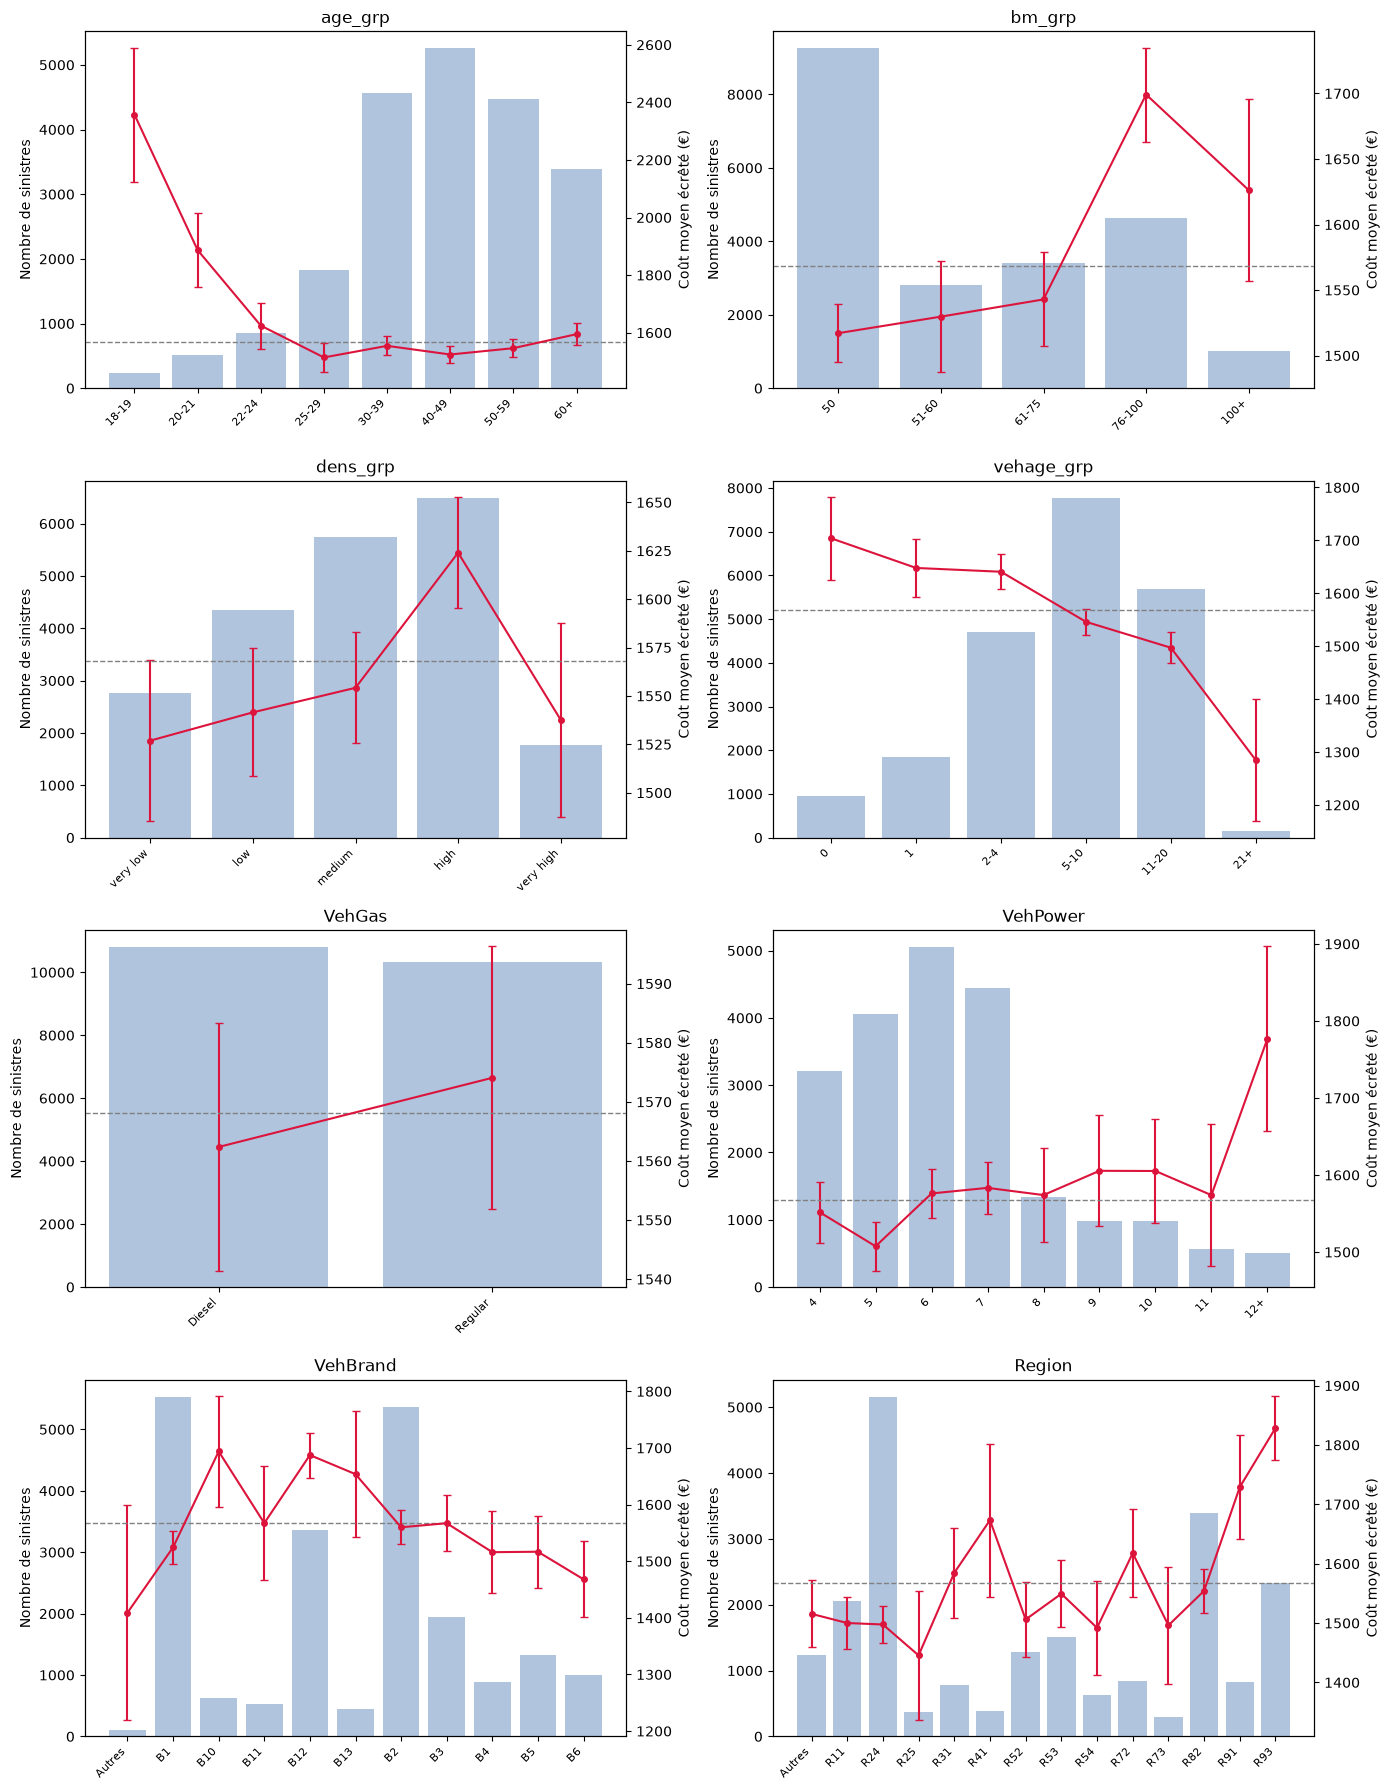

In [45]:
VARIABLES_SEV = ["age_grp", "bm_grp", "dens_grp", "vehage_grp",
                 "VehGas", "VehPower", "VehBrand", "Region"]

ORDRE_POWER = [str(i) for i in range(4, 12)] + ["12+"]
for d in (sev_train, sev_test):
    d["VehPower"] = pd.Categorical(d["VehPower"], categories=ORDRE_POWER, ordered=True)

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
for col, ax in zip(VARIABLES_SEV, axes.flat):
    plot_sev_par_groupe(sev_train, col, ax=ax)
plt.tight_layout()

for col in VARIABLES_SEV:
    print(table_severite(sev_train, col, forfaits=FORFAITS).round(3))
    print(comparer_tranches_sev(sev_train, col).round(2))

Synthèse des observations par modalité pour le coût moyen :

|Variable|Forme|Nombre de catégorie sous 989 sinistres|Structure à tester|
|-|-|-|-|
|Âge|Pente chez les jeunes, plateau, puis remontée à 70+|2|18-19 / 20-21 / 22-24 / 25-69 / 70+|
|Bonus-malus|saut au-delà de 75|0|≤75 / 76+|
|Densité|quasi plat|0|retrait (aucune info apportée)|
|Âge du véhicule|baisse régulière|2|0-4 / 5-10 / 11+|
|Carburant|aucun effet|0|retrait|
|Puissance|plat sauf 12+|4|≤11 / 12+, ou retrait|
|Marque|B12, B10, B13 au-dessus|5||
|Région|R93 et R91 au-dessus|7|à garder|


In [46]:
# Les plus gros sinistres sont-ils bien chez les 18-19 ans ?
print(sev_train.nlargest(5, "ClaimAmount")[["ClaimAmount", "DrivAge", "age_grp", "bm_grp"]])

# Les graves frappent-ils tous les âges de la même façon ?
grave = sev_train["ClaimAmount"] > SEUIL_GRAVES
print(grave.groupby(sev_train["age_grp"], observed=True).agg(["sum", "mean"]))

# B12 est-elle une marque de véhicules neufs ?
print(pd.crosstab(sev_train["VehBrand"], sev_train["vehage_grp"], normalize="index").round(2))

       ClaimAmount  DrivAge age_grp  bm_grp
7781    4075400.56       19   18-19  76-100
12601   1403057.40       20   20-21  76-100
9286    1301172.60       18   18-19  76-100
14387    774411.50       40   40-49   61-75
2315     390742.27       57   50-59      50
         sum      mean
age_grp               
18-19     10  0.041322
20-21     12  0.023576
22-24      9  0.010453
25-29     17  0.009269
30-39     43  0.009432
40-49     45  0.008562
50-59     42  0.009381
60+       34  0.010018
vehage_grp     0     1   2-4  5-10  11-20   21+
VehBrand                                       
Autres      0.08  0.06  0.19  0.25   0.39  0.02
B1          0.02  0.05  0.18  0.38   0.35  0.01
B10         0.04  0.08  0.20  0.31   0.33  0.04
B11         0.04  0.08  0.14  0.41   0.32  0.02
B12         0.14  0.25  0.39  0.18   0.04  0.00
B13         0.04  0.06  0.18  0.48   0.24  0.00
B2          0.03  0.06  0.18  0.39   0.33  0.01
B3          0.04  0.07  0.23  0.41   0.25  0.01
B4          0.04  0.07  0.

- Les trois plus gros sinistres viennent bien des 18-20 ans avec un bonus-malus 76-100.

- Les sinistrres graves ne frappent pas toutes les catégorie d'Âge uniformément. On remarque qu'un sinistre d'un conducteur de moins de 22 ans à environ trois fois plus de chance d'être grave. Or l'encrêtement repose sur l'idée que les graves "frappent n'importe quel porfil". C'est le cas à partir de 22 ans mais faux en dessous. Les 70+ sont un peu au dessus. On retrouve donc le fait que les accidents chez les jeunes conducteurs sont plus couteux en moyenne, pas seulement dans les valeurs extrêmes.

Il y une différence à faire cependant : 
  - Comment on vient de le voir, la survenance d'un sinistre grave est plus probable chez les jeunes conducteurs. Il faut donc que le chargement tienne compte de cette probabilité.
  - Cependant, le coût d'un sinistre grave et son montant au delà du seuil est complètement aléatoire et indépendant du profil du conducteur. Aucune variable ne peut prédire 4 M€ plutôt que 50 000 €.

Ainsi, une solution simple est de segmenter la charge k dépendamment de l'âge du conducteur : `k_segment = c × taux de graves du segment`, où `c` est choisi de tel sorte que la charge totale soit la même que celle calculée avec un k uniforme.

In [47]:
jeune = sev_train["age_grp"].isin(["18-19", "20-21"])
segment = np.where(jeune, "moins_22", "22_plus")
taux = grave.groupby(segment).mean()
charge_ecretee = sev_train.groupby(segment)["montant_ecrete"].sum()

c = excedent / (taux * charge_ecretee).sum()
K_SEGMENT = c * taux
print("k uniforme :", K_GRAVES)
print(K_SEGMENT)


k uniforme : 0.47429758898069635
22_plus     0.431583
moins_22    1.356185
Name: ClaimAmount, dtype: float64


- le taux des jeunes repose sur 22 graves, soit une erreur relative de 21% sur le taux de graves (d'après la formule : `erreur relative = √N / N = 1 / √N ` (Même qu'en phase 1, écart-type d'un nombre d'évênement)). Le rapport ×2,9 vaut à peu près ±0,6, mais il reste nettement au-dessus de 1.

- La frontière à 22 ans a été choisie après avoir vu les donées. Il faudra la vérifier hors échantillon.

In [48]:


glm_sev = smf.glm(
    FORMULE_SEVERITE_BASE,
    data=sev_train,
    family=sm.families.Gamma(link=sm.families.links.Log()),
).fit()

print(glm_sev.summary())


                 Generalized Linear Model Regression Results                  
Dep. Variable:         montant_ecrete   No. Observations:                21132
Model:                            GLM   Df Residuals:                    21082
Model Family:                   Gamma   Df Model:                           49
Link Function:                    Log   Scale:                          1.9509
Method:                          IRLS   Log-Likelihood:            -1.7969e+05
Date:                Tue, 10 Nov 2026   Deviance:                       21726.
Time:                        20:11:23   Pearson chi2:                 4.11e+04
No. Iterations:                    14   Pseudo R-squ. (CS):           0.007042
Covariance Type:            nonrobust                                         
                                                    coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------

In [49]:
cols = ["age_grp2", "bm_grp", "dens_grp", "vehage_grp", "VehGas", "vehpower_grp_2", "VehBrand", "Region"]
attendu = sum(sev_train[c].nunique() -1 for c in cols)
assert glm_sev.df_model == attendu, (glm_sev.df_model, attendu)
print("Convergence :", glm_sev.converged, "  paramètres :", attendu + 1)
print("Prédit / observé :", glm_sev.fittedvalues.sum() / sev_train["montant_ecrete"].sum())
print("φ :", glm_sev.scale)

Convergence : True   paramètres : 50
Prédit / observé : 1.0001928906676631
φ : 1.9509401104608155


In [50]:
grille_sev = pd.DataFrame({
    "facteur_sev": np.exp(glm_sev.params),
    "z_sev": glm_sev.tvalues,
})
grille_freq = pd.read_csv("../outputs/grille_frequence.csv", index_col=0)

grilles = grille_freq[["facteur", "z"]].rename(
    columns={"facteur": "facteur_freq", "z": "z_freq"}
).join(grille_sev, how="outer")

grilles.round(3)

,facteur_freq,z_freq,facteur_sev,z_sev
"C(Region, Treatment('R24'))[T.Autres]",0.941,-2.259,0.986,-0.310
"C(Region, Treatment('R24'))[T.R11]",0.908,-3.533,0.958,-0.962
"C(Region, Treatment('R24'))[T.R25]",0.948,-1.157,0.951,-0.667
"C(Region, Treatment('R24'))[T.R31]",0.877,-3.723,1.053,0.938
"C(Region, Treatment('R24'))[T.R41]",0.783,-5.275,1.143,1.797
"C(Region, Treatment('R24'))[T.R52]",0.942,-2.152,1.003,0.076
"C(Region, Treatment('R24'))[T.R53]",1.031,1.201,1.038,0.886
"C(Region, Treatment('R24'))[T.R54]",0.891,-3.047,0.985,-0.247
"C(Region, Treatment('R24'))[T.R72]",0.848,-4.954,1.065,1.198
"C(Region, Treatment('R24'))[T.R73]",0.828,-4.171,0.995,-0.058


In [51]:
r = glm_sev.resid_deviance
contrib = r ** 2
petits = sev_train["ClaimAmount"] < 40

print("Part de la déviance due aux sinistres < 40 € :", contrib[petits].sum() / contrib.sum())
print("Part de ces sinistres dans la base :", petits.mean())
print(sev_train.assign(resid=r).loc[r.abs().nlargest(10).index,
      ["ClaimAmount", "montant_ecrete", "age_grp2", "resid"]])

Part de la déviance due aux sinistres < 40 € : 0.06801524811958146
Part de ces sinistres dans la base : 0.010174143479083854
       ClaimAmount  montant_ecrete age_grp2     resid
14736    182500.00       16351.621    30-39  4.398041
6634      44927.41       16351.621    30-39  4.265636
11279    203172.00       16351.621    25-29  4.217846
13707     37622.00       16351.621    40-49  4.211754
15029     46105.94       16351.621    30-39  4.202975
11155     20602.99       16351.621    40-49  4.177441
6467     121959.21       16351.621      50+  4.157609
12367     39850.00       16351.621      50+  4.142583
18178     42450.00       16351.621      50+  4.142003
14039     21594.95       16351.621    30-39  4.131423


**Modèle.** GLM Gamma à lien log sur le montant écrêté, une ligne par sinistre, sans offset.
50 paramètres, mêmes effets principaux et mêmes références qu'en fréquence.
Calibration globale : +0,02 %, aucun recalage nécessaire.

**Hypothèse rejetée.** Le saut du bonus-malus au-delà de 75 n'est pas un effet de l'âge déguisé :
il persiste à âge égal.

**Des effets qui se compensent.** R93 a moins d'accidents que R24 (×0,91) mais des accidents plus
chers (×1,20), soit environ ×1,10 en prime pure. C'est le cas de trois régions, pas une tendance
générale (corrélation de −0,33 entre les facteurs de fréquence et de sévérité des 13 régions).

**Résidus.** Les sinistres de moins de 40 € représentent 1 % de la base mais 6,8 % de la déviance.
Les plus gros résidus sont les sinistres écrêtés au seuil : la déviance Gamma pénalise les écarts
en rapport, dans les deux sens.


|Variable|	Fréquence|	Sévérité|
|-|-|-|
|Âge 18-19	|×2,17 (11,6 σ)|	×1,47 (4,1 σ)
|Âge 20-21	|×1,53	|×1,18 (2,4 σ)
|Âge 40 et plus	|×1,52 à 1,55	|≈ 1
|Bonus-malus 76-100	|×2,28	|×1,15 (4,5 σ)
|Bonus-malus 100+	|×5,51	|×1,11 (2,1 σ)
|Véhicule neuf	|×3,11	|×1,07 (1,3 σ)
|Densité	|jusqu’à ×1,24	|aucun effet (z < 1,3)|
|Diesel	|×0,94 (5,1 σ)	|×1,003 (0,1 σ)|
|Puissance	|ruptures nettes	|aucun effet, sauf 12+ à ×1,13 (1,9 σ)|
|R93	|×0,91 (−3,9 σ)	|×1,20 (5,0 σ)|
|R91	|×0,88 (−4,1 σ)	|×1,15 (2,6 σ)|

Si on observe les facteurs en relation avec les écarts-types, on constate que la sévérité ne dépend que de l'âge, du bonus-malus et de la région. Les autres variables n'ont pas d'effet significatif sur le coût moyen. En effet, la densité, le carburant, la puissance et presque tout l’âge du véhicule influent sur la probabilité d’un accident et non son coût.

|Test	|Raison|
|-|-|
|Retrait de dens_grp	|4 coefficients, aucun au-delà de 1,3 σ|
|Retrait de VehGas	|z = 0,1|
|vehpower_grp_2 → ≤11 / 12+, ou retrait	|plat sauf 12+|
|vehage_grp → 0-4 / 5-10 / 11+	|0, 1 et 2-4 tous entre ×1,05 et ×1,06|
|Âge : 22 et plus en un bloc, ou 70+ séparé	|plateau après 22 ans ; le 70+ de l’étape C est noyé dans le 50+ de la fréquence|
|Bonus-malus → 50-75 / 76+	|51-60 et 61-75 non significatifs|
|age40p:dense|	héritée de la fréquence, à vérifier|
|Gamma seule ou mélange|	forfaits|
|Seuils de 97,5 % et 99,5 %	|sensibilité de l’écrêtement|
|Sans les montants de moins de 40 €	|sensibilité de la déviance|

In [53]:
base     = ajuster_gamma(FORMULE_SEVERITE_BASE, sev_train)
sans_dens = ajuster_gamma(formule_sev(sans(TERMES_SEV_BASE, "dens")), sev_train)
sans_gas  = ajuster_gamma(formule_sev(sans(TERMES_SEV_BASE, "gas")),  sev_train)

pd.DataFrame({
    "retrait dens_grp": comparer_glm_gamma(sans_dens, base),
    "retrait VehGas":   comparer_glm_gamma(sans_gas,  base),
})

,retrait dens_grp,retrait VehGas
ddl,4.0000,1.0000
phi,1.9510,1.9510
LR,1.9100,0.0200
seuil_test,9.4900,3.8400
seuil_aic,8.0000,2.0000
seuil_bic,39.8300,9.9600
p_value,0.7527,0.9017


**dens_grp** : LR de 1.91 pour 4 paramètres retirés, cette perte est largement compensée par la simplification du modèle pour les scores AIC et BIC. Le retrait est confirmé.

**VehGas** : LR de 0.02 pour 1 paramètre retiré, cette perte est largement compensée par la simplification du modèle pour les scores AIC et BIC. Le retrait est confirmé.

Attention : ces retraits ne concerne que le modèle de sévérité. Pour le modèle de fréquence, ces variables sont conservées.

In [ ]:
sev_train = colonnes_sev(sev_train)
sev_test  = colonnes_sev(sev_test)

TERMES_SEV_2 = sans(sans(TERMES_SEV_BASE, "dens"), "gas")
base2 = ajuster_gamma(formule_sev(TERMES_SEV_2), sev_train)

t_power  = remplacer(TERMES_SEV_2, "power",  "C(power_sev, Treatment('<=11'))")
t_vehage = remplacer(TERMES_SEV_2, "vehage", "C(vehage_sev, Treatment('5-10'))")
t_bm3    = remplacer(TERMES_SEV_2, "bm",     "C(bm_sev3, Treatment('50-75'))")
t_bm2    = remplacer(TERMES_SEV_2, "bm",     "C(bm_sev2, Treatment('50-75'))")

m_power      = ajuster_gamma(formule_sev(t_power), sev_train)
m_power_sans = ajuster_gamma(formule_sev(sans(TERMES_SEV_2, "power")), sev_train)
m_vehage     = ajuster_gamma(formule_sev(t_vehage), sev_train)
m_bm3        = ajuster_gamma(formule_sev(t_bm3), sev_train)
m_bm2        = ajuster_gamma(formule_sev(t_bm2), sev_train)

pd.DataFrame({
    "puissance ≤11 / 12+":         comparer_glm_gamma(m_power, base2),
    "puis retrait de la puissance": comparer_glm_gamma(m_power_sans, m_power),
    "âge véhicule 0-4 / 5-10 / 11+": comparer_glm_gamma(m_vehage, base2),
    "bonus-malus en 3 modalités":   comparer_glm_gamma(m_bm3, base2),
    "puis en 2 modalités":          comparer_glm_gamma(m_bm2, m_bm3),
})